In this file we look at individual country examples to explore implementation of the peak tester work flow

In [3]:
import os, sys
sys.path.append('../scripts')

from peak_tester import EmissionsPeakTest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_indexing as pix
from pandas_indexing import *

import joblib

from helper_functions import HiddenPrints, segment_by_peaks, combine_countries

# Country CO2 emissions

In [4]:
#USA
usa_gdp_tester = EmissionsPeakTest()
usa_gdp_tester.load_historical_data(
            'wdi_gdp.csv', region='USA', year_range=range(1990, 2025))
usa_gdp_tester.characterize_noise(method='broken_trend')

Loaded historical data: 1990-2024
Data points: 35
Max breakpoints: 7
using t-dist distribution to calculate noise
Fitted t-distribution to innovations: df = 3.0
Autocorrelation analysis:

  Lag-1 autocorr: 0.073
  Residual σ (post-autocorrelation): 0.2
  Has significant autocorr: False
  Likelihood of autocorr: 0.3421973432303521
Noise characterization complete:
  Method used: broken_trend


In [5]:
usa_em_tester = EmissionsPeakTest()
usa_em_tester.load_historical_data(
            'gcb_hist_co2.csv', region='USA', year_range=range(1990, 2025))
usa_em_tester.characterize_noise(method='broken_trend', noise_type='t-dist', ignore_years=[2020])

Loaded historical data: 1990-2024
Data points: 35
Max breakpoints: 7
using t-dist distribution to calculate noise
Fitted t-distribution to innovations: df = 47065564.8
Autocorrelation analysis:

  Lag-1 autocorr: -0.059
  Residual σ (post-autocorrelation): 71.7
  Has significant autocorr: False
  Likelihood of autocorr: 0.28041120625556926
Noise characterization complete:
  Method used: broken_trend


In [7]:
usa_ci_tester = EmissionsPeakTest()
usa_ci_tester.load_historical_data(
            'carbon_intensity_gdp.csv', region='USA', year_range=range(1990, 2025))
usa_ci_tester.characterize_noise(method='broken_trend')

Loaded historical data: 1990-2024
Data points: 35
Max breakpoints: 7
using t-dist distribution to calculate noise
Fitted t-distribution to innovations: df = 7827609349.2
Autocorrelation analysis:

  Lag-1 autocorr: 0.155
  Residual σ (post-autocorrelation): 4.9
  Has significant autocorr: False
  Likelihood of autocorr: 0.6423343642250922
Noise characterization complete:
  Method used: broken_trend


In [22]:
peak_testers_seq = joblib.load(
    '../outputs/data/country_analysis/peak_testers_growing_window_sequential.joblib'
)
peak_prob_expanding_window_sequential = pd.read_csv(
    '../outputs/data/country_analysis/peaked_isos_growing_window_sequential.csv',
    index_col=0
)

peak_testers_slope = joblib.load(
    '../outputs/data/country_analysis/peak_testers_growing_window_slope.joblib'
)
peak_prob_expanding_window_slope = pd.read_csv(
    '../outputs/data/country_analysis/peaked_isos_growing_window_slope.csv',
    index_col=0
)

peak_prob_seq = peak_prob_expanding_window_sequential['USA']
peak_prob_slope = peak_prob_expanding_window_slope['USA']

Using AR(1) noise generator with φ=0.66, mean=0.000, sigma=5.309
Using AR(1) noise generator with φ=0.45, mean=-0.000, sigma=5.531
Using AR(1) noise generator with φ=0.55, mean=-0.000, sigma=11.216
White noise residuals are not distributed close to zero
Mean of residuals = 1.4874977127267408
Using AR(1) noise generator with φ=0.77, mean=0.000, sigma=187.274
Using AR(1) noise generator with φ=0.61, mean=0.000, sigma=71.674
Using AR(1) noise generator with φ=0.68, mean=0.000, sigma=38.205
White noise residuals are not distributed close to zero
Mean of residuals = -1.101408495201954
Using AR(1) noise generator with φ=0.45, mean=-0.000, sigma=25.191
White noise residuals are not distributed close to zero
Mean of residuals = -0.9446544137963211
White noise residuals are not distributed close to zero
Mean of residuals = -8.772993631465752
Using AR(1) noise generator with φ=0.29, mean=-0.000, sigma=21.900
Using AR(1) noise generator with φ=0.43, mean=0.000, sigma=15.954
White noise residuals 

In [26]:
# CI
peak_testers_ci = joblib.load(
    '../outputs/data/country_analysis/peak_testers_growing_window_slope_carbon_intensity.joblib'
)
peak_prob_expanding_window_slope_ci = pd.read_csv(
    '../outputs/data/country_analysis/peaked_isos_growing_window_slope_carbon_intensity.csv',
    index_col=0
)


peak_prob_slope_ci = peak_prob_expanding_window_slope_ci['USA']

Using AR(1) noise generator with φ=0.47, mean=-0.000, sigma=3.729
Using AR(1) noise generator with φ=0.54, mean=0.000, sigma=13.909
Using white noise generator with mean=0,  σ=5.069


<Axes: >

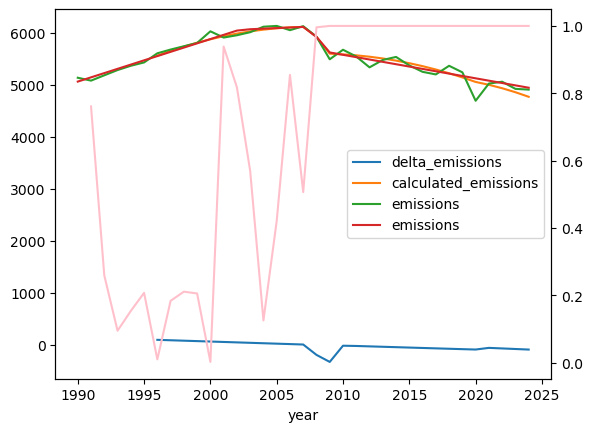

In [23]:
# calculate change in emissions based on change in carbon intensity and GDP, and compare to actual change in emissions.
del_em_dict = {}
calc_em_dict = {}

for yr in range(1996,2025):
    ci_x_gdp = (usa_ci_tester.trend.loc[yr] * usa_gdp_tester.trend.loc[yr])
    del_em = (usa_ci_tester.trend.loc[yr] * usa_gdp_tester.trend.loc[yr]) - (usa_ci_tester.trend.loc[yr-1] * usa_gdp_tester.trend.loc[yr-1])
    del_em_dict[yr] = del_em
    calc_em_dict[yr] = ci_x_gdp

delta_em = pd.DataFrame(del_em_dict, index=['delta_emissions']).T
calc_em = pd.DataFrame(calc_em_dict, index=['calculated_emissions']).T

em_trend = pd.DataFrame(usa_em_tester.trend, columns = ['emissions']).reset_index().rename(columns={'index':'year'}).set_index('year')


fig, ax = plt.subplots()
delta_em.plot(ax=ax, label='Calculated change in emissions')
calc_em.plot(ax=ax, label='Calculated emissions')
usa_em_tester.historical_data.plot(ax=ax, label='Historical emissions') 

em_trend.plot(ax=ax, label='Trend in historical emissions')

ax2 = ax.twinx()
peak_prob_expanding_window_sequential['USA'].plot(ax=ax2, color='pink', label='Peak Probability')

For the US, the peak coincides with a drop in GDP due to the financial crash. Emissions were already close to a plateau.
GDP trend x CI trend gives a close result to the emissions trend - are there any situations when this wouldn't happen?
Is this relevant for our analysis of global peaking? because the trend won't dip down at first.
What do we need to be convinced of a structural peak? 

AttributeError: 'NoneType' object has no attribute 'index'

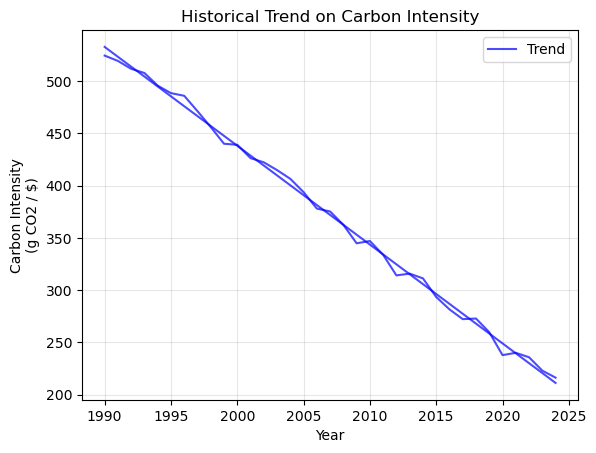

In [24]:
f, ax = plt.subplots()
usa_ci_tester._plot_historical_trend(ax)
usa_ci_tester._plot_historical_and_test_data(ax)

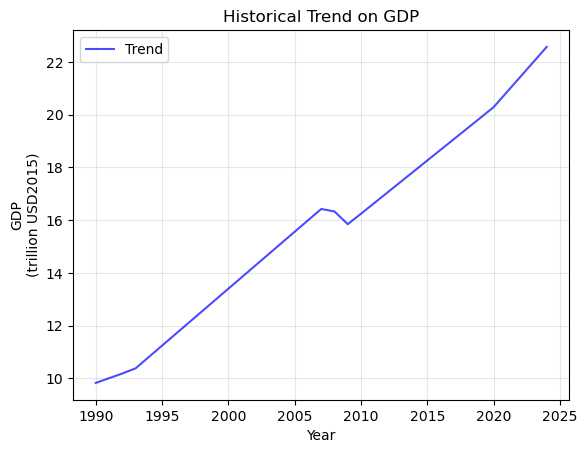

In [25]:
f, ax = plt.subplots()
usa_gdp_tester._plot_historical_trend(ax)

<Axes: xlabel='year'>

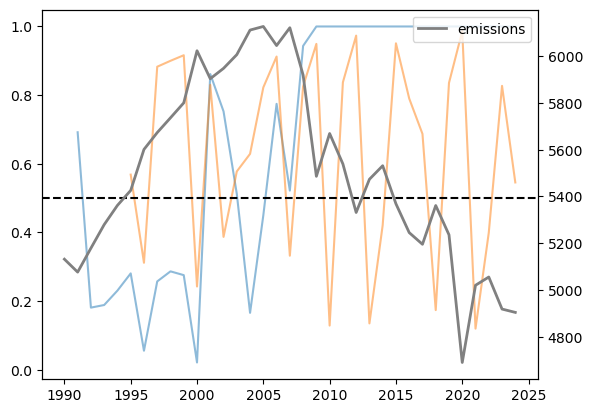

In [34]:
f, ax = plt.subplots()
peak_prob_expanding_window_slope['USA'].plot(ax=ax,alpha=0.5)
peak_prob_expanding_window_slope_ci['USA'].plot(ax=ax,alpha=0.5)

ax.axhline(y=0.5,color='k',ls='--')

ax2 = ax.twinx()
usa_em_tester.historical_data.plot(ax=ax2,color='grey',lw=2)

<Axes: xlabel='year'>

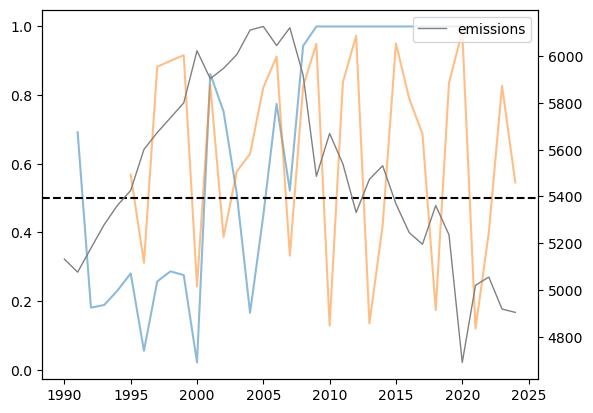

In [36]:
f, ax = plt.subplots()
peak_prob_expanding_window_slope['USA'].plot(ax=ax,alpha=0.5)
peak_prob_expanding_window_slope_ci['USA'].plot(ax=ax,alpha=0.5)

ax.axhline(y=0.5,color='k',ls='--')

ax2 = ax.twinx()
usa_em_tester.historical_data.plot(ax=ax2,color='grey',lw=1)